<a href="https://colab.research.google.com/github/chikuu303/customer-churn-ml-project/blob/main/deep_learning_nlp_text_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip install -q tensorflow scikit-learn matplotlib pandas

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [3]:

texts = [
    "I love this product", "This is amazing",
    "Very happy with my purchase", "Excellent quality",
    "I really enjoyed this", "The product is wonderful",
    "Fantastic experience", "I am very satisfied",
    "This works perfectly", "Absolutely great",
    "I hate this product", "This is terrible",
    "Very disappointed with my purchase", "Poor quality",
    "I really disliked this", "The product is awful",
    "Horrible experience", "I am very unhappy",
    "This works badly", "Absolutely disappointing",
    "The service was excellent", "I would recommend this",
    "I am impressed with the results", "Really good experience",
    "The service was disappointing", "I would not recommend this",
    "The results are very poor", "I regret buying this",
    "Everything was perfect", "Everything went wrong"
]

labels = [
    1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
    1, 1, 1, 1, 0, 0, 0, 0, 1, 0
]

df = pd.DataFrame({
    "text": texts,
    "sentiment": labels
})

print(df.head())
print("\nDataset shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())

                          text  sentiment
0          I love this product          1
1              This is amazing          1
2  Very happy with my purchase          1
3            Excellent quality          1
4        I really enjoyed this          1

Dataset shape: (30, 2)

Missing values:
 text         0
sentiment    0
dtype: int64


In [4]:

# Separate text and target labels
X = df["text"]
y = df["sentiment"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 24
Testing samples: 6


In [6]:

# Step 4: Split the dataset
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X = df["text"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 5: Convert text into numerical features
vectorizer = TfidfVectorizer(
    max_features=1000,
    ngram_range=(1, 2)
)

X_train_tfidf = vectorizer.fit_transform(X_train).toarray()
X_test_tfidf = vectorizer.transform(X_test).toarray()

print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)
print("Step 4 and Step 5 completed successfully!")

Training data shape: (24, 88)
Testing data shape: (6, 88)
Step 4 and Step 5 completed successfully!


In [7]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    tf.keras.Input(shape=(X_train_tfidf.shape[1],)),

    Dense(64, activation="relu"),
    BatchNormalization(),
    Dropout(0.4),

    Dense(32, activation="relu"),
    BatchNormalization(),
    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         5,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,193 (32.00 KB)

 Trainable params: 8,001 (31.25 KB)

 Non-trainable params: 192 (768.00 B)

In [8]:

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train_tfidf,
    y_train,
    epochs=40,
    batch_size=4,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

print("Model training completed!")

Epoch 1/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 247ms/step - accuracy: 0.5263 - loss: 0.8865 - val_accuracy: 0.4000 - val_loss: 0.6798
Epoch 2/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.6842 - loss: 0.7414 - val_accuracy: 0.4000 - val_loss: 0.6822
Epoch 3/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - accuracy: 0.4737 - loss: 0.8705 - val_accuracy: 0.4000 - val_loss: 0.6852
Epoch 4/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - accuracy: 0.5789 - loss: 0.7245 - val_accuracy: 0.6000 - val_loss: 0.6875
Epoch 5/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 166ms/step - accuracy: 0.5263 - loss: 0.7752 - val_accuracy: 0.6000 - val_loss: 0.6909
Epoch 6/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - accuracy: 0.6842 - loss: 0.6235 - val_accuracy: 0.6000 - val_loss: 0.6939
Model training completed!


In [9]:

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train_tfidf,
    y_train,
    epochs=40,
    batch_size=4,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

print("Model training completed!")

Epoch 1/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.5263 - loss: 0.9362 - val_accuracy: 0.4000 - val_loss: 0.6818
Epoch 2/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.5263 - loss: 0.8306 - val_accuracy: 0.4000 - val_loss: 0.6836
Epoch 3/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.5263 - loss: 0.7366 - val_accuracy: 0.4000 - val_loss: 0.6855
Epoch 4/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.5789 - loss: 0.7765 - val_accuracy: 0.6000 - val_loss: 0.6867
Epoch 5/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.5263 - loss: 0.7097 - val_accuracy: 0.6000 - val_loss: 0.6891
Epoch 6/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.7368 - loss: 0.6102 - val_accuracy: 0.6000 - val_loss: 0.6914
Model training completed!


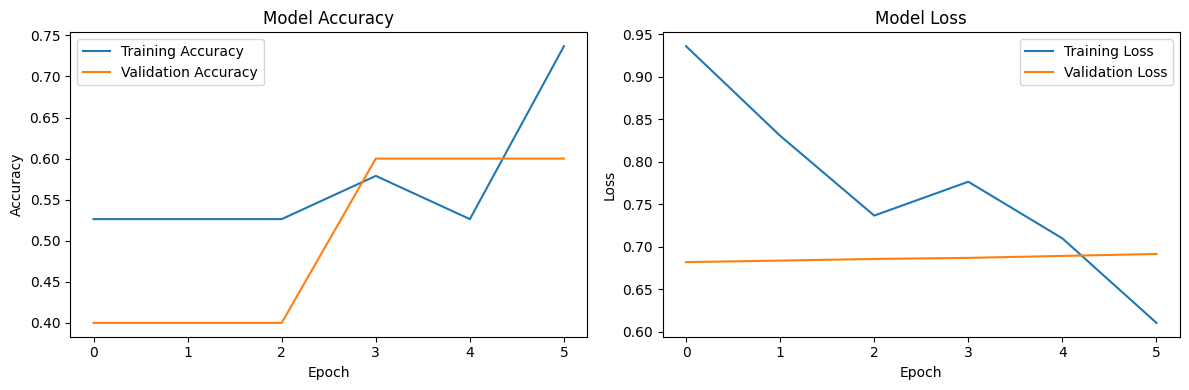

In [10]:

# Plot training and validation accuracy/loss
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step
Test Accuracy: 0.3333

Classification Report:
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00         3
    Positive       0.40      0.67      0.50         3

    accuracy                           0.33         6
   macro avg       0.20      0.33      0.25         6
weighted avg       0.20      0.33      0.25         6



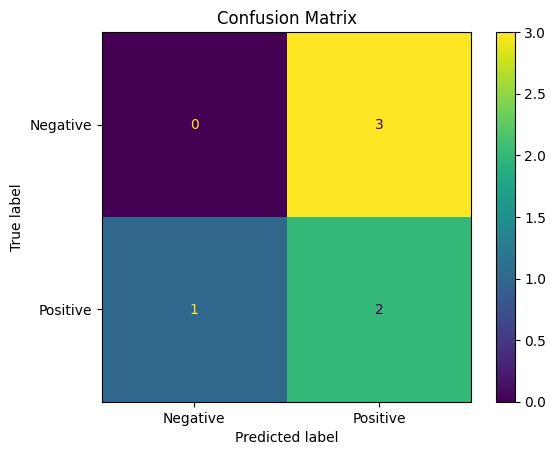

In [11]:
import matplotlib.pyplot as plt


from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict probabilities and convert them into class labels
y_prob = model.predict(X_test_tfidf).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Negative", "Positive"]
)
plt.title("Confusion Matrix")
plt.show()

In [12]:

def predict_sentiment(text):
    text_vector = vectorizer.transform([text]).toarray()

    probability = float(model.predict(text_vector, verbose=0)[0][0])

    if probability >= 0.5:
        sentiment = "Positive"
        confidence = probability * 100
    else:
        sentiment = "Negative"
        confidence = (1 - probability) * 100

    print("Input text:", text)
    print("Predicted sentiment:", sentiment)
    print(f"Model confidence: {confidence:.2f}%")

predict_sentiment("I really love this amazing product")
print()
predict_sentiment("This product is disappointing and terrible")
print()
predict_sentiment("The product arrived yesterday")

Input text: I really love this amazing product
Predicted sentiment: Negative
Model confidence: 50.57%

Input text: This product is disappointing and terrible
Predicted sentiment: Positive
Model confidence: 51.44%

Input text: The product arrived yesterday
Predicted sentiment: Negative
Model confidence: 50.79%


In [13]:

# Save the neural network
model.save("sentiment_analysis_model.keras")

# Save the TF-IDF vectorizer
import pickle

with open("tfidf_vectorizer.pkl", "wb") as file:
    pickle.dump(vectorizer, file)

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!


In [14]:

from google.colab import files

files.download("sentiment_analysis_model.keras")
files.download("tfidf_vectorizer.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>